In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
from fastai.vision.all import *
import pandas as pd

In [6]:
path = Path('/kaggle/input/competitions/state-farm-distracted-driver-detection/imgs')

15577 6847


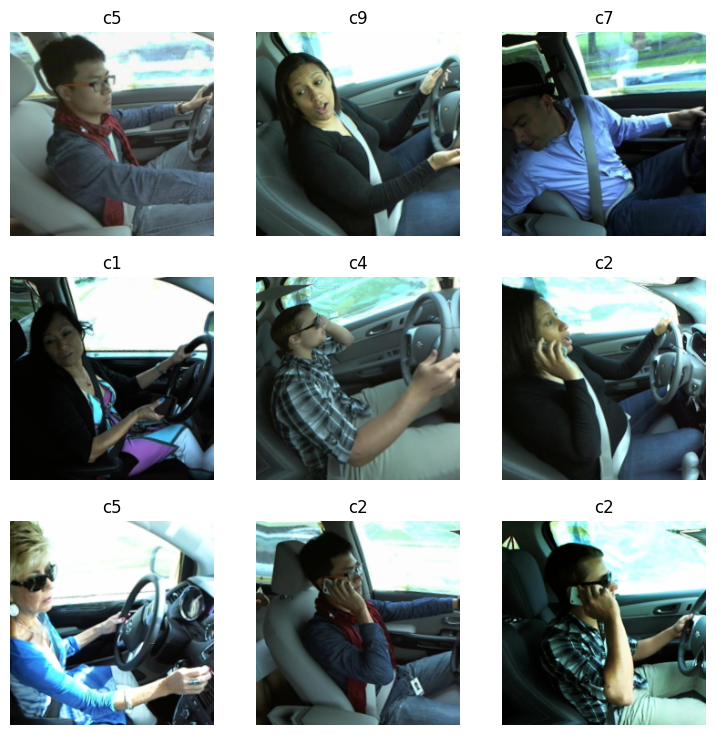

In [9]:
root = path.parent
df = pd.read_csv(root/'driver_imgs_list.csv')

# Hold out more drivers for a less noisy validation score
val_drivers = df.subject.unique()[:7]
df['is_valid'] = df.subject.isin(val_drivers)
df['fname'] = 'train/' + df.classname + '/' + df.img

dls = ImageDataLoaders.from_df(
    df, path, fn_col='fname', label_col='classname',
    valid_col='is_valid',
    item_tfms=Resize(224),
    batch_tfms=aug_transforms(do_flip=False, max_rotate=10, max_zoom=1.2,
                              max_lighting=0.4, max_warp=0.2),
    bs=64
)

print(len(dls.train_ds), len(dls.valid_ds))   # valid should be roughly 5,500-6,000 with 7 drivers
dls.show_batch()

In [10]:
learn = vision_learner(dls, resnet34, metrics=error_rate,
                       loss_func=LabelSmoothingCrossEntropy(), wd=0.1).to_fp16()
learn.path = Path('/kaggle/working')
learn.fine_tune(4, 1e-3, cbs=SaveModelCallback(monitor='valid_loss'))

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 170MB/s] 


epoch,train_loss,valid_loss,error_rate,time
0,1.673553,1.845238,0.543158,01:50


Better model found at epoch 0 with valid_loss value: 1.8452378511428833.


epoch,train_loss,valid_loss,error_rate,time
0,0.901984,1.309635,0.325836,01:15
1,0.705754,1.038603,0.205637,01:13
2,0.624189,1.014150,0.205199,01:15
3,0.601524,0.989303,0.187527,01:13


Better model found at epoch 0 with valid_loss value: 1.309634804725647.
Better model found at epoch 1 with valid_loss value: 1.0386031866073608.
Better model found at epoch 2 with valid_loss value: 1.0141499042510986.
Better model found at epoch 3 with valid_loss value: 0.9893027544021606.


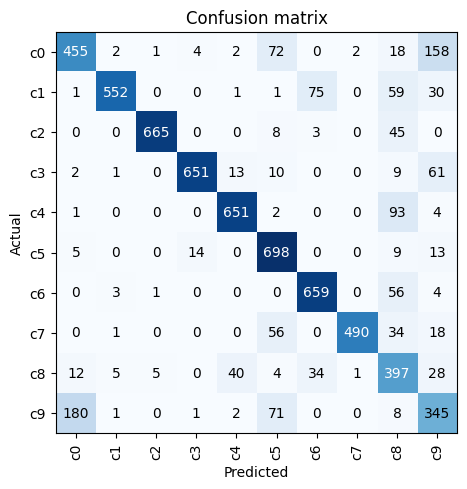

In [11]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

In [12]:
import torch, json

learn.to_fp32()                       # undo to_fp16() so CPU inference works
model = learn.model.eval().cpu()

# Input size must match your item_tfms, e.g. 224 for Resize(224), (240, 320) for Resize((240, 320))
H, W = 224, 224
traced = torch.jit.trace(model, torch.randn(1, 3, H, W))
traced.save('/kaggle/working/model.pt')

json.dump(list(learn.dls.vocab), open('/kaggle/working/vocab.json', 'w'))

In [13]:
from fastai.vision.all import *

img_path = (path/'train/c6').ls()[0]          # any image
_, _, fastai_probs = learn.predict(PILImage.create(img_path))   # run before or after export

loaded = torch.jit.load('/kaggle/working/model.pt', map_location='cpu').eval()
x = learn.dls.test_dl([img_path]).one_batch()[0].cpu().float()  # fastai's own preprocessing
with torch.no_grad():
    ts_probs = torch.softmax(loaded(x), dim=1)[0]

print(torch.allclose(fastai_probs, ts_probs, atol=1e-3))   # should be True

True


In [14]:
import numpy as np, pandas as pd

sub = pd.read_csv(root/'sample_submission.csv')
test_files = [path/'test'/f for f in sub.img]

test_dl = learn.dls.test_dl(test_files, bs=128)    # uses the same Resize(224), no augmentation
probs, _ = learn.get_preds(dl=test_dl)
probs = probs.numpy()

# Safety clip, then renormalize so each row sums to 1
probs = np.clip(probs, 0.01, 0.99)
probs = probs / probs.sum(axis=1, keepdims=True)

out = pd.DataFrame(probs, columns=list(learn.dls.vocab))
out.insert(0, 'img', sub.img.values)
out = out[sub.columns]                              # force the same column order as the sample
out.to_csv('/kaggle/working/submission.csv', index=False)

print(out.shape, out.iloc[:, 1:].sum(axis=1).describe())

(79726, 11) count    7.972600e+04
mean     1.000000e+00
std      6.101882e-08
min      9.999998e-01
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64
